In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
# Data Loading (PyTorch)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Simple transforms for CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465),
                         std=(0.2023, 0.1994, 0.2010))
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)

# Optionally subsample for speed (e.g., 10000 training examples)
max_train = 10000
if len(train_full) > max_train:
    train_full = Subset(train_full, range(max_train))

# Train/validation split (e.g., 80/20)
val_frac = 0.2
val_size = int(len(train_full) * val_frac)
train_size = len(train_full) - val_size
train_dataset, val_dataset = random_split(train_full, [train_size, val_size])

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

len(train_dataset), len(val_dataset), len(test_dataset)

(8000, 2000, 10000)

In [3]:
class PlainCNN(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),  # 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),  # 8x8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

plain_cnn = PlainCNN().to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(plain_cnn)

289194

In [4]:
# Residual Block & Small ResNet
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_projection=False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if use_projection or (in_channels != out_channels) or (stride != 1):
            self.proj = nn.Conv2d(in_channels, out_channels, kernel_size=1,
                                  stride=stride, bias=False)
            self.proj_bn = nn.BatchNorm2d(out_channels)
        else:
            self.proj = None

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out, inplace=True)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.proj is not None:
            identity = self.proj(x)
            identity = self.proj_bn(identity)

        out += identity
        out = F.relu(out, inplace=True)
        return out


class SmallResNet(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Stage 1: 32 channels
        self.layer1 = nn.Sequential(
            BasicBlock(32, 32),
            BasicBlock(32, 32)
        )

        # Stage 2: 64 channels, spatial downsample
        self.layer2 = nn.Sequential(
            BasicBlock(32, 64, stride=2, use_projection=True),
            BasicBlock(64, 64)
        )

        # Stage 3: 128 channels, spatial downsample
        self.layer3 = nn.Sequential(
            BasicBlock(64, 128, stride=2, use_projection=True),
            BasicBlock(128, 128)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

small_resnet = SmallResNet().to(device)
count_parameters(small_resnet)

696618

In [5]:
from collections import defaultdict
import math
import time

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += x.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def eval_model(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += x.size(0)

    return total_loss / total, correct / total

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

def run_experiment(model, name, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = defaultdict(list)
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = eval_model(model, val_loader, criterion)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

    history_df = pd.DataFrame(history)
    history_df["model"] = name
    return model, history_df


plain_cnn_model, plain_hist = run_experiment(PlainCNN(), "PlainCNN", epochs=8, lr=1e-3)
resnet_model, resnet_hist = run_experiment(SmallResNet(), "SmallResNet", epochs=8, lr=1e-3)

summary = pd.DataFrame({
    "model": ["PlainCNN", "SmallResNet"],
    "params": [count_parameters(plain_cnn_model), count_parameters(resnet_model)],
    "final_val_acc": [
        plain_hist["val_acc"].iloc[-1],
        resnet_hist["val_acc"].iloc[-1],
    ],
    "final_train_acc": [
        plain_hist["train_acc"].iloc[-1],
        resnet_hist["train_acc"].iloc[-1],
    ]
})
summary

,model,params,final_val_acc,final_train_acc
0,PlainCNN,289194,0.5165,0.758875
1,SmallResNet,696618,0.6465,0.793375


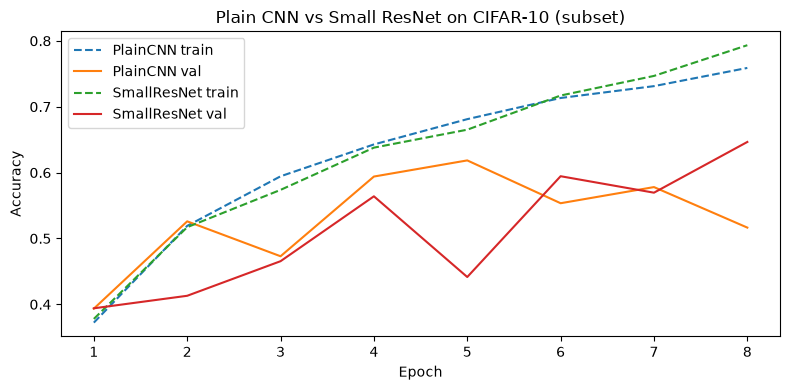

In [7]:
plt.figure(figsize=(8, 4))

for hist, label in [(plain_hist, "PlainCNN"), (resnet_hist, "SmallResNet")]:
    plt.plot(hist["epoch"], hist["train_acc"], linestyle="--", label=f"{label} train")
    plt.plot(hist["epoch"], hist["val_acc"], linestyle="-", label=f"{label} val")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Plain CNN vs Small ResNet on CIFAR-10 (subset)")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
def make_plain_stack(num_blocks=6, channels=64):
    layers = []
    in_ch = 3
    for _ in range(num_blocks):
        layers.append(nn.Conv2d(in_ch, channels, kernel_size=3, padding=1, bias=False))
        layers.append(nn.BatchNorm2d(channels))
        layers.append(nn.ReLU(inplace=True))
        in_ch = channels
    layers.append(nn.AdaptiveAvgPool2d((1, 1)))
    return nn.Sequential(*layers)


class DeepPlainCNN(nn.Module):
    def __init__(self, num_classes=10, num_blocks=6, channels=64):
        super().__init__()
        self.features = make_plain_stack(num_blocks=num_blocks, channels=channels)
        self.fc = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


class DeepResNet(nn.Module):
    def __init__(self, num_classes=10, num_blocks=6, channels=64):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
        blocks = [BasicBlock(channels, channels) for _ in range(num_blocks)]
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


deep_plain = DeepPlainCNN(num_blocks=8, channels=64).to(device)
deep_resnet = DeepResNet(num_blocks=8, channels=64).to(device)

count_parameters(deep_plain), count_parameters(deep_resnet)

(261450, 594378)

In [9]:
import numpy as np

def measure_grad_norms(model, loader, steps=1):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

    model.train()
    grad_norms = []

    step = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()

        # record gradient norms for conv layers only
        conv_norms = []
        for name, p in model.named_parameters():
            if "weight" in name and p.grad is not None and p.ndim == 4:  # conv weights
                conv_norms.append(p.grad.detach().norm().item())
        grad_norms.append(conv_norms)

        optimizer.step()
        step += 1
        if step >= steps:
            break

    # average across steps
    max_len = max(len(g) for g in grad_norms)
    avg = np.zeros(max_len)
    counts = np.zeros(max_len)
    for g in grad_norms:
        for i, v in enumerate(g):
            avg[i] += v
            counts[i] += 1
    avg /= np.maximum(counts, 1)
    return avg


plain_grad_norms = measure_grad_norms(deep_plain, train_loader, steps=3)
resnet_grad_norms = measure_grad_norms(deep_resnet, train_loader, steps=3)

plain_grad_norms, resnet_grad_norms

(array([0.15184978, 0.52481926, 0.4235291 , 0.46624596, 0.40166265,
        0.33348445, 0.33019865, 0.40052112]),
 array([0.66095519, 1.85468205, 1.57547458, 1.13675137, 1.06458714,
        0.94165885, 0.94550623, 0.89049536, 0.89199475, 0.88939484,
        0.86603761, 0.80063707, 0.88362362, 0.83144504, 0.80231371,
        0.65399877, 0.75877188]))

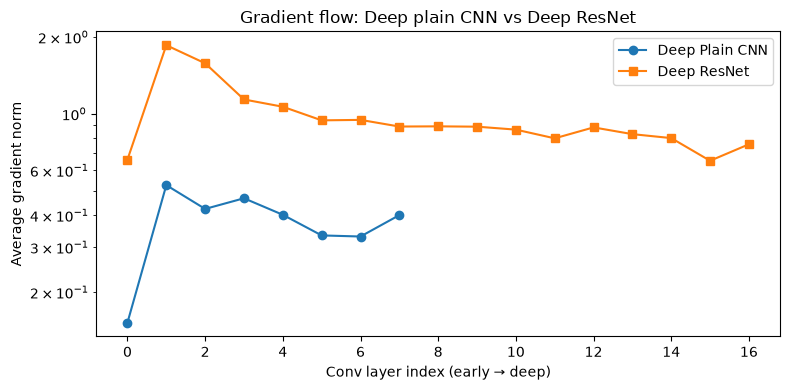

,layer_idx,plain_grad_norm,resnet_grad_norm
0,0,0.151850,0.660955
1,1,0.524819,1.854682
2,2,0.423529,1.575475
3,3,0.466246,1.136751
4,4,0.401663,1.064587
5,5,0.333484,0.941659
6,6,0.330199,0.945506
7,7,0.400521,0.890495


In [10]:
layer_idx_plain = np.arange(len(plain_grad_norms))
layer_idx_res = np.arange(len(resnet_grad_norms))

plt.figure(figsize=(8, 4))
plt.plot(layer_idx_plain, plain_grad_norms, marker="o", linestyle="-", label="Deep Plain CNN")
plt.plot(layer_idx_res, resnet_grad_norms, marker="s", linestyle="-", label="Deep ResNet")

plt.xlabel("Conv layer index (early → deep)")
plt.ylabel("Average gradient norm")
plt.title("Gradient flow: Deep plain CNN vs Deep ResNet")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()

grad_table = pd.DataFrame({
    "layer_idx": layer_idx_plain,
    "plain_grad_norm": plain_grad_norms,
    "resnet_grad_norm": resnet_grad_norms[:len(layer_idx_plain)]
})
grad_table